In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.naive_bayes import ComplementNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, RocCurveDisplay, ConfusionMatrixDisplay
from scipy import stats
from sklearn.base import clone
%matplotlib inline

#Clenning ReactionTypes data

In [ ]:
df=pd.read_excel('/content/Bank_Personal_Loan_Modelling.xlsx', sheet_name='Data')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [ ]:
df.head(10)

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1
5,6,37,13,29,92121,4,0.4,2,155,0,0,0,1,0
6,7,53,27,72,91711,2,1.5,2,0,0,0,0,1,0
7,8,50,24,22,93943,1,0.3,3,0,0,0,0,0,1
8,9,35,10,81,90089,3,0.6,2,104,0,0,0,1,0
9,10,34,9,180,93023,1,8.9,3,0,1,0,0,0,0


In [ ]:
df.corr()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,1.000000,-0.008473,-0.008326,-0.017695,0.013432,-0.016797,-0.024672,0.021463,-0.013920,-0.024801,-0.016972,-0.006909,-0.002528,0.017028
Age,-0.008473,1.000000,0.994215,-0.055269,-0.029216,-0.046418,-0.052030,0.041334,-0.012539,-0.007726,-0.000436,0.008043,0.013702,0.007681
Experience,-0.008326,0.994215,1.000000,-0.046574,-0.028626,-0.052563,-0.050089,0.013152,-0.010582,-0.007413,-0.001232,0.010353,0.013898,0.008967
Income,-0.017695,-0.055269,-0.046574,1.000000,-0.016410,-0.157501,0.645993,-0.187524,0.206806,0.502462,-0.002616,0.169738,0.014206,-0.002385
ZIP Code,0.013432,-0.029216,-0.028626,-0.016410,1.000000,0.011778,-0.004068,-0.017377,0.007383,0.000107,0.004704,0.019972,0.016990,0.007691
Family,-0.016797,-0.046418,-0.052563,-0.157501,0.011778,1.000000,-0.109285,0.064929,-0.020445,0.061367,0.019994,0.014110,0.010354,0.011588
CCAvg,-0.024672,-0.052030,-0.050089,0.645993,-0.004068,-0.109285,1.000000,-0.136138,0.109909,0.366891,0.015087,0.136537,-0.003620,-0.006686
Education,0.021463,0.041334,0.013152,-0.187524,-0.017377,0.064929,-0.136138,1.000000,-0.033327,0.136722,-0.010812,0.013934,-0.015004,-0.011014
Mortgage,-0.013920,-0.012539,-0.010582,0.206806,0.007383,-0.020445,0.109909,-0.033327,1.000000,0.142095,-0.005411,0.089311,-0.005995,-0.007231
Personal Loan,-0.024801,-0.007726,-0.007413,0.502462,0.000107,0.061367,0.366891,0.136722,0.142095,1.000000,0.021954,0.316355,0.006278,0.002802


from matplotlib import pyplot as plt
_df_0['ID'].plot(kind='hist', bins=20, title='ID')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['Age'].plot(kind='hist', bins=20, title='Age')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['Experience'].plot(kind='hist', bins=20, title='Experience')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['Income'].plot(kind='hist', bins=20, title='Income')
plt.gca().spines[['top', 'right',]].set_visible(False)

...

from matplotlib import pyplot as plt
_df_7.plot(kind='scatter', x='Income', y='ZIP Code', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_8['ID'].plot(kind='line', figsize=(8, 4), title='ID')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_9['Age'].plot(kind='line', figsize=(8, 4), title='Age')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['Experience'].plot(kind='line', figsize=(8, 4), title='Experience')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_11['Income'].plot(kind='line', figsize=(8, 4), title='Income')
plt.gca().spines[['top', 'right']].set_visible(False)

* Personal Loan is highly correlated with Income, CD_Account, CCAvg.
* Experience is highly correlated with Age. (ρ = 0.99)
* CCAvg is correlated with Income to a good extent. (ρ = 0.58)

# noisy tr

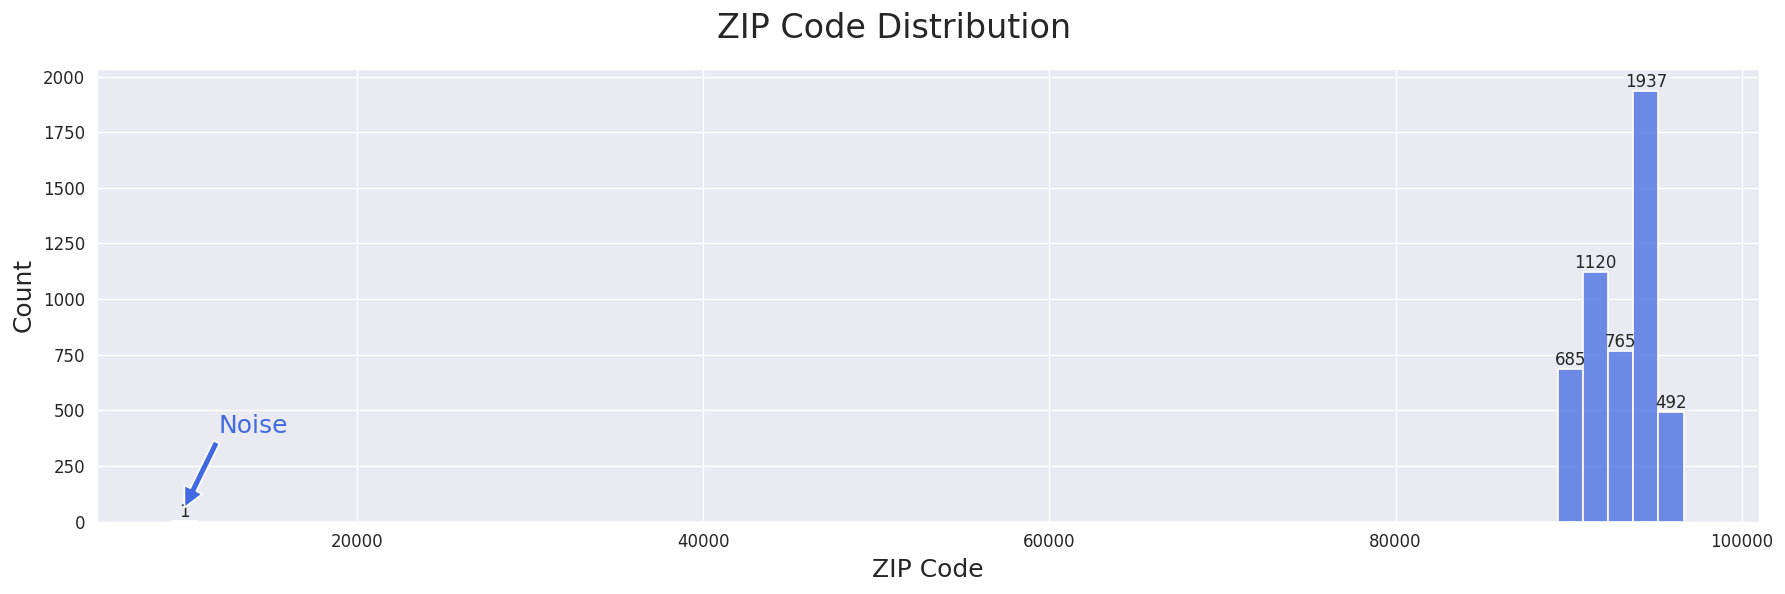

In [ ]:

# Set the style of the graph
sns.set_style('darkgrid')
color = 'royalblue'

# Plot histogram
plt.figure(figsize=(15,5), dpi=120)
graph = sns.histplot(x='ZIP Code', data=df, bins=60, color=color)

# Show non-zero values of the individual bars
labels = [str(v) if v else '' for v in graph.containers[0].datavalues]
graph.bar_label(graph.containers[0], labels=labels)

plt.annotate('Noise', xy=(10000,60), xytext=(12000,400), color=color, fontsize=15,
             arrowprops=dict(facecolor=color, shrink=0.01))
plt.xlabel('ZIP Code', fontsize=15)
plt.ylabel('Count', fontsize=15)
plt.suptitle('ZIP Code Distribution', fontsize=20)
plt.tight_layout()
plt.show()

In [ ]:

df[df['ZIP Code']<20000]
df.drop(df[df['ZIP Code']<20000].index, inplace=True)
df.reset_index(drop=True, inplace =True)


In [ ]:

df[df['Experience']<0]['Experience'].count()
df[df['Experience']<0]['Experience'].value_counts()
df['Experience'] = df['Experience'].apply(abs)

# outlier treatment

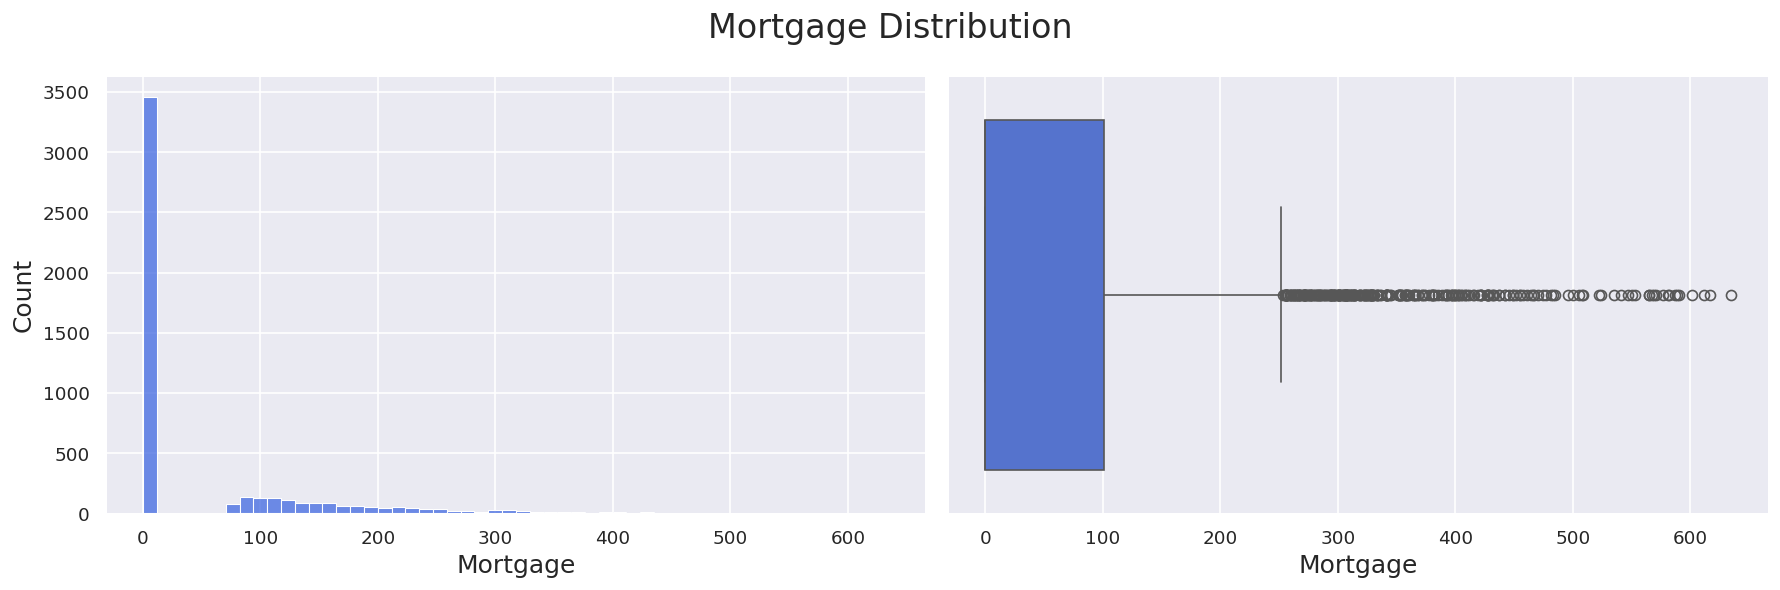

In [ ]:
sns.set(rc = {'axes.labelsize' : 15})
fig, ax = plt.subplots(1, 2, figsize=(15,5), dpi=120)
sns.histplot(x='Mortgage', data=df, color='royalblue', ax=ax[0])
sns.boxplot(x='Mortgage', data=df, color='royalblue', ax=ax[1])
plt.suptitle('Mortgage Distribution', fontsize=20)
plt.tight_layout()
plt.show()

In [ ]:

df[stats.zscore(df['Mortgage'])>3]['Mortgage'].count()
outlier_indexes = df[stats.zscore(df['Mortgage'])>3].index
df.drop(outlier_indexes, inplace=True)
df.reset_index(drop=True, inplace=True)

# missing values

In [ ]:
df.isnull().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

#Duplicate

In [ ]:
df[df.duplicated(keep=False)].sum().sum()

0.0

#Feature Transformation

In the dataset, CCAVG represents average monthly credit card spending, but Income represents the amount of annual income. To make the units of the features equal, we convert average monthly credit card spending to annual:

In [ ]:
df['CCAvg'] = df['CCAvg']*12

In [ ]:
# Define a list containing the names of important categorical features in the dataset
Cat_Features = ['CD Account','Education','Family','Securities Account','Online','Securities Account']

# Define the target name in a variable for simplicity
Target = 'Personal Loan'

In [ ]:
X = df.drop('Personal Loan', axis=1)
y = df['Personal Loan']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

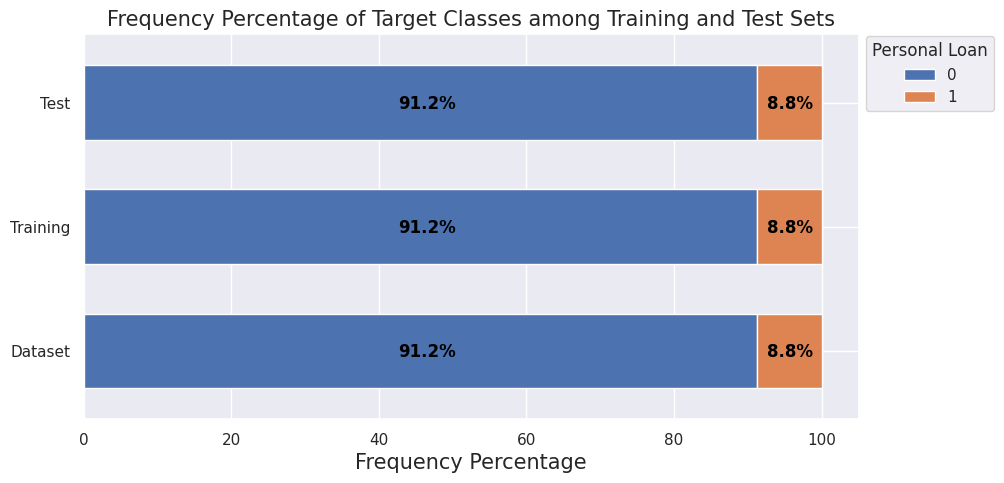

In [ ]:
# Define a dataframe containing frequency percentages
df_perc = pd.concat([y.value_counts(normalize=True).mul(100).round(1),
                     y_train.value_counts(normalize=True).mul(100).round(1),
                     y_test.value_counts(normalize=True).mul(100).round(1)], axis=1)
df_perc.columns=['Dataset','Training','Test']
df_perc = df_perc.T

# Plot frequency percentages barplot
df_perc.plot(kind='barh', stacked=True, figsize=(10,5), width=0.6)

# Add the percentages to our plot
for idx, val in enumerate([*df_perc.index.values]):
    for (percentage, y_location) in zip(df_perc.loc[val], df_perc.loc[val].cumsum()):
        plt.text(x=(y_location - percentage) + (percentage / 2)-3,
                 y=idx - 0.05,
                 s=f'{percentage}%',
                 color="black",
                 fontsize=12,
                 fontweight="bold")

plt.legend(title='Personal Loan', loc=(1.01,0.8))
plt.xlabel('Frequency Percentage', fontsize=15)
plt.title('Frequency Percentage of Target Classes among Training and Test Sets', fontsize=15)
plt.show()

#KNN Classifier

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier


# Define a range of k values to try
k_values = [5, 7, 9, 11, 13, 15, 17, 19]

# Initialize an empty list to store cross-validation scores
cv_scores = []

# Perform cross-validation for each k value
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

# Find the optimal value of k
optimal_k = k_values[cv_scores.index(max(cv_scores))]

print(f"Optimal value of k: {optimal_k}")


Optimal value of k: 9


In [ ]:
print(cv_scores)

[0.9106584488431964, 0.9112406867508908, 0.9115339368830238, 0.9115339368830238, 0.9115339368830238, 0.9115339368830238, 0.9115339368830238, 0.9115339368830238]


#SVM Classifier

In [ ]:
import numpy as np
import h5py
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.svm import SVC  # Import the Support Vec
# Create an SVM classifier with a linear kernel
svm_classifier = SVC(kernel='poly')

# Fit the model on the training data
svm_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = svm_classifier.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.2f}")


Test Accuracy: 0.91


In [ ]:
y_train.shape

(15774,)

#NB Classifier

In [ ]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
# Create a Gaussian Naive Bayes classifier
nb_classifier = GaussianNB()

# Fit the model on the training data
nb_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = nb_classifier.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.2f}")



Test Accuracy: 0.89


#AdaBoost

In [ ]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score
# Create an AdaBoost classifier
ada_classifier = AdaBoostClassifier(n_estimators=10, learning_rate=0.001, random_state=True)

# Fit the model on the training data
ada_classifier.fit(X_train, y_train)

# Make predictions on the test data
y_pred = ada_classifier.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.2f}")


Test Accuracy: 0.91


#AdaBoost with SVM

/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Accuracy: 0.911504424778761


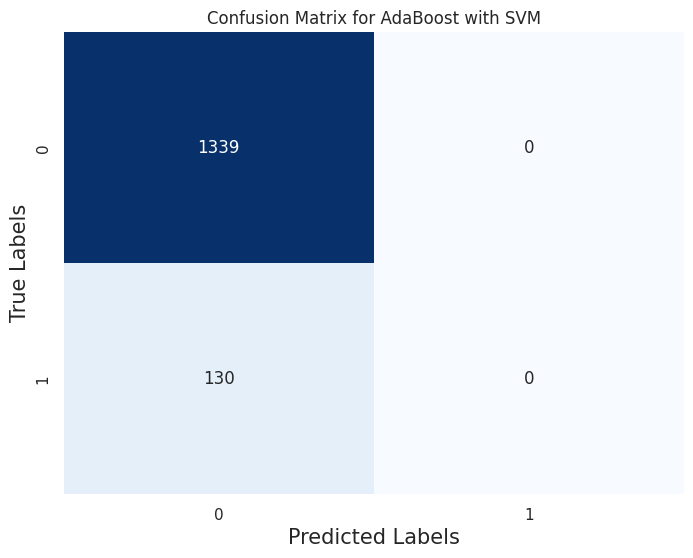

In [ ]:
# Load necessary libraries
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create an SVM classifier
svc = SVC(probability=True, kernel='poly')

# Create an AdaBoost classifier with SVM as the base estimator
abc_svm = AdaBoostClassifier(base_estimator=svc, n_estimators=50)

# Fit the model to your training data
abc_svm.fit(X_train, y_train)

# Make predictions on the test data
y_pred_svm = abc_svm.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

# Create a confusion matrix
conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svm, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for AdaBoost with SVM')
plt.show()


#AdaBoost with NB

Accuracy: 0.818924438393465


/usr/local/lib/python3.10/dist-packages/sklearn/ensemble/_base.py:166: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


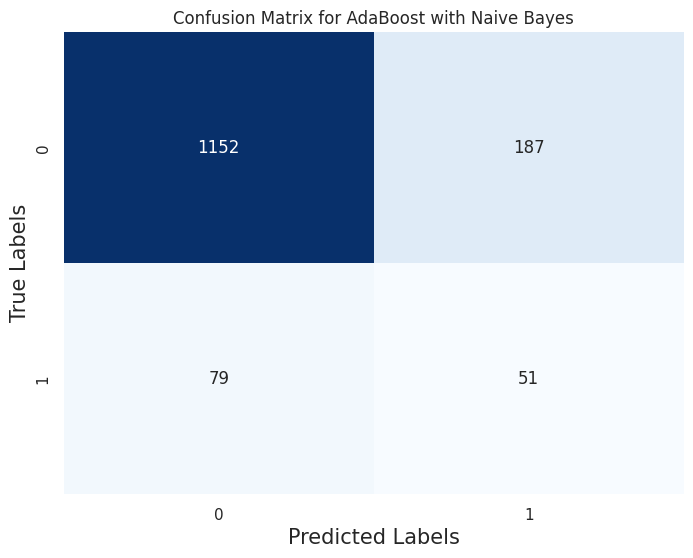

In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create an NB classifier
nb = MultinomialNB()

# Create an AdaBoost classifier with NB as the base estimator
abc_nb = AdaBoostClassifier(base_estimator=nb, n_estimators=10)

# Fit the model to your training data
abc_nb.fit(X_train, y_train)

# Make predictions on the test data
y_pred_nb = abc_nb.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

# Create a confusion matrix
conf_matrix_nb = confusion_matrix(y_test, y_pred_nb)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_nb, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for AdaBoost with Naive Bayes')
plt.show()


#K-means

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:8

Optimal number of clusters for KMeans: 9


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Centroids of the clusters:
[[-3.74700271e-16  4.57966998e-16  4.99600361e-16 -3.46944695e-16
   6.93889390e-17 -7.91033905e-16 -3.67761377e-16  6.93889390e-17
   4.16333634e-17  4.64905892e-16  4.16333634e-17 -3.33066907e-16
   4.02455846e-16  1.00000000e+00 -2.77555756e-16  4.30211422e-16
   7.50000000e+01]
 [ 1.20736754e-15 -1.49880108e-15 -1.20736754e-15  3.33559783e-01
  -2.12330153e-15  1.05471187e-15  1.41553436e-15 -2.12330153e-15
   4.85722573e-17  9.85322934e-16 -2.24820162e-15  1.85962357e-15
   3.48505435e-01 -1.70696790e-15  1.90125693e-15  3.17934783e-01
   1.23783967e+01]
 [-7.56339436e-16  5.48172618e-16  8.46545056e-16 -4.30211422e-16
   4.16333634e-17 -1.05471187e-15  9.15933995e-16  5.01765003e-01
   4.16333634e-17  8.53483950e-16 -1.66533454e-15  4.98234997e-01
  -1.20736754e-15 -1.14491749e-15  1.34614542e-15  5.27355937e-16
   3.24911750e+01]
 [-4.16333634e-16  4.64905892e-16  5.55111512e-16 -3.46944695e-16
   6.93889390e-17  1.00000000e+00 -3.40005801e-16  6.93889

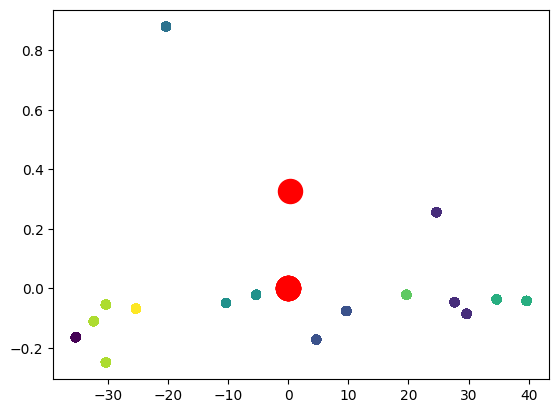

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Determine the optimal number of clusters for KMeans
silhouette_scores = []
K = range(2, 10)
for k in K:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(x_train)
    silhouette_scores.append(silhouette_score(x_train, kmeans.labels_))

optimal_K = K[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal number of clusters for KMeans: {optimal_K}")

# Apply KMeans with the optimal number of clusters
kmeans = KMeans(n_clusters=optimal_K)
kmeans.fit(x_train)

# Print the centroids
print("Centroids of the clusters:")
print(kmeans.cluster_centers_)

# Visualize the clusters and centroids
pca = PCA(n_components=2)
x_train_pca = pca.fit_transform(x_train)
plt.scatter(x_train_pca[:, 0], x_train_pca[:, 1], c=kmeans.labels_)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='red')
plt.show()



#AgglomerativeClustering

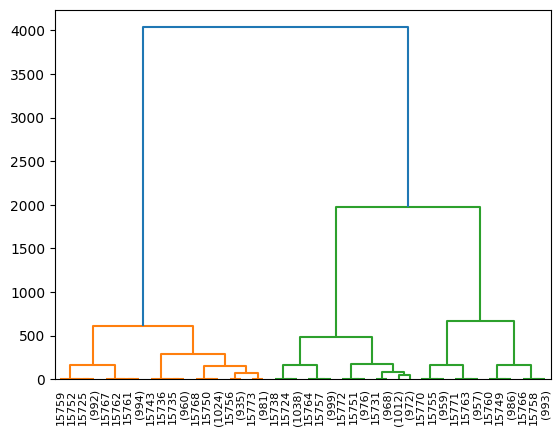

In [ ]:
# Instantiate AgglomerativeClustering with distance_threshold=0 and n_clusters=None
# This means the hierarchy of clusters is constructed incrementally without deciding the number of clusters beforehand
agglo = AgglomerativeClustering(distance_threshold=0, n_clusters=None)

# Fit the model to the training data
agglo.fit(x_train)

# Initialize an array of zeros with the same shape as agglo.children_
counts = np.zeros(agglo.children_.shape[0])

# Get the number of samples in the labels of the model
n_samples = len(agglo.labels_)

# Loop over each pair of children
for i, merge in enumerate(agglo.children_):
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            # If the index of the child node is less than the number of samples, it is a leaf node
            current_count += 1
        else:
            # If the index of the child node is greater or equal to the number of samples, it is a non-leaf node and we add the count of that child node to the current count
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

# Create a linkage matrix by concatenating the children, distances and counts
linkage_matrix = np.column_stack([agglo.children_, agglo.distances_, counts]).astype(float)

# Plot the dendrogram using the linkage matrix
dendrogram(linkage_matrix, truncate_mode='level', p=5)
#print(linkage_matrix)

# Display the plot
plt.show()
